# Denial of service: the batch concurrency cap (2.7)

Scoring a batch of URLs costs the server real CPU, so a flood of big batches sent at once can 
tie up every worker and leave the API unable to answer anyone else (DoS). 

The defence is a semaphore: only `BATCH_CONCURRENCY` (integer) batches run at a time, 
and any extra batch is turned away at once with 503 and a `Retry-After` header, 
instead of piling up until the server freezes.

One expensive request is sent and others are still answered promptly, then send many at 
once and show the excess is rejected with 503. 

Use *Run All*.

In [5]:
import sys
import threading
import time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
BACKEND = HERE if (HERE / "app" / "main.py").is_file() else HERE.parent
SEC = BACKEND / "security_eval"
sys.path.insert(0, str(BACKEND))
import harness as h

FLOODERS = 24        # heavy batches in flight at once
BATCH_URLS = 200     # URLs per batch, enough that scoring one costs real CPU
PROBE_URL = "google.com"
CAP = 4              # BATCH_CONCURRENCY with the defence on
UNCAPPED = 10_000    # effectively no cap (defence off)
DURATION = 10        # seconds to sustain the flood, so both runs collect a real sample

# Why these: 24 batches far exceed a 4 slot cap, so the 503 path is well tested.
# A 200-URL batch is heavy enough that an ordinary request has to compete for CPU while the
# flood runs

h.ensure_db()
BIG_BATCH = {"urls": ["google.com", "paypal-account-verify.top/login"] * (BATCH_URLS // 2)}

## Flood the batch endpoint, and time an ordinary request during the flood

In [6]:
def flood_and_probe(concurrency):
    # BATCH_MAX_URLS is raised so the heavy batch is allowed
    proc = h.start_server(BATCH_CONCURRENCY=concurrency, BATCH_MAX_URLS=BATCH_URLS)
    try:
        probe_ms, codes = [], []
        stop = threading.Event()

        def probe():   # one ordinary user, checking a single URL over and over during the flood
            while not stop.is_set():
                status, _, ms = h.post("/api/check", {"url": PROBE_URL})
                if status == 200:
                    probe_ms.append(ms)

        def flood():   # keep FLOODERS heavy batches in flight until the window closes
            with ThreadPoolExecutor(max_workers=FLOODERS) as pool:
                while not stop.is_set():
                    futures = [pool.submit(lambda: h.post("/api/check/batch", BIG_BATCH)[0]) for _ in range(FLOODERS)]
                    codes.extend(f.result() for f in futures)

        threads = [threading.Thread(target=probe), threading.Thread(target=flood)]
        for t in threads: # start all threads
            t.start()
        time.sleep(DURATION)
        stop.set()
        for t in threads: # wait to finish
            t.join()
    finally:
        h.stop_server(proc)
    return codes, probe_ms


off_codes, off_probe = flood_and_probe(UNCAPPED)
on_codes, on_probe   = flood_and_probe(CAP)
print("done measuring")

done measuring


## Results

In [7]:
def summarise(codes, probe):
    med = pd.Series(probe).median() if probe else float("nan")
    return codes.count(200), codes.count(503), codes.count(0), med, len(probe)

rows = [["off (uncapped)", *summarise(off_codes, off_probe)],
        [f"on (cap {CAP})", *summarise(on_codes, on_probe)]]
table = pd.DataFrame(rows, columns=["defence", "batches_200", "batches_503", "batches_dropped", "probe_median_ms", "probe_samples"])
print(table.to_string(index=False))

pd.DataFrame([{"defence": "off", "probe_ms": v} for v in off_probe] + [{"defence": "on", "probe_ms": v} for v in on_probe]).to_csv(SEC / "dos_probe_raw.csv", index=False)

print()
print(f"[cap OFF] {table.batches_200[0]} heavy batches were all accepted and run; an ordinary request "
      f"waited a median {table.probe_median_ms[0]:.0f} ms behind the flood")
print(f"[cap ON ] {table.batches_503[1]} excess batches were 503'd instead of running; an ordinary "
      f"request stayed at a median {table.probe_median_ms[1]:.0f} ms")

       defence  batches_200  batches_503  batches_dropped  probe_median_ms  probe_samples
off (uncapped)          144            0                0         923.2707             10
    on (cap 4)          100          500                0         344.5864             31

[cap OFF] 144 heavy batches were all accepted and run; an ordinary request waited a median 923 ms behind the flood
[cap ON ] 500 excess batches were 503'd instead of running; an ordinary request stayed at a median 345 ms


## Plot

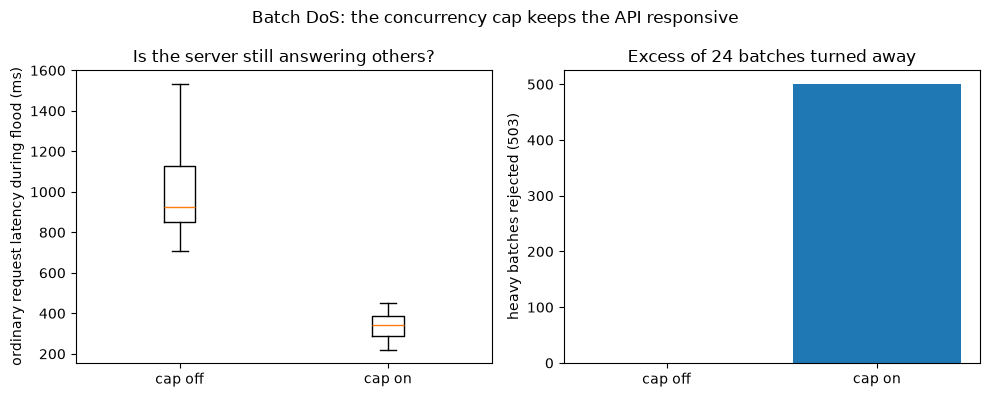

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.boxplot([off_probe or [0], on_probe or [0]], showfliers=False)
ax1.set_xticks([1, 2])
ax1.set_xticklabels(["cap off", "cap on"])
ax1.set_ylabel("ordinary request latency during flood (ms)")
ax1.set_title("Is the server still answering others?")

ax2.bar(["cap off", "cap on"], [off_codes.count(503), on_codes.count(503)])
ax2.set_ylabel("heavy batches rejected (503)")
ax2.set_title(f"Excess of {FLOODERS} batches turned away")

fig.suptitle("Batch DoS: the concurrency cap keeps the API responsive")
fig.tight_layout()
fig.savefig(SEC / "dos.png", dpi=120)
plt.show()

## What the numbers say

With the cap off, every heavy batch runs at once and an ordinary request has to wait
behind them, so latency for everyone else climbs. With the cap on, only `BATCH_CONCURRENCY`
batches run, the rest get an immediate 503 with `Retry-After`, and an ordinary request is
answered quickly. Prevents the server from freezing.

What the cap does not fix:

- It protects CPU and worker slots, not raw bandwidth. A flood large enough to saturate
  the network link is a job for a host or CDN, not application code, which is out of scope 
  on a single machine.
- One batch is still allowed to be large, up to `BATCH_MAX_URLS`, so the per-request size
  cap and the body-size limit from the 2.3 hygiene still complement.

Cost: legitimate bulk users share the `BATCH_CONCURRENCY` slots, so at peak some of them
get a 503 and retry after the delay. Tradeoff is throughput-versus-availability